# Predicting freight cost

##### Project Objective
Build an ML model that predicts the expected freight/transportation cost from invoice and shipment information.

The model can help a company:

Estimate freight cost before receiving the invoice.
Identify unusually high freight charges.
Detect potential billing errors.
Improve logistics budgeting and cost forecasting.
Compare expected vs. actual freight charges.

In [2]:
import pandas as pd
import sqlite3
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [6]:
connect = sqlite3.connect('../Data/inventory.db')
table = pd.read_sql_query("SELECT name FROM sqlite_master WHERE type='table'", connect)
table

,name
0,purchases
1,purchase_prices
2,vendor_invoice
3,begin_inventory
4,end_inventory


In [ ]:
for t in table['name']:
    print('table name: ',t)
    df= pd.read_sql_query(f'select * from {t}', connect)
    df.head()

table name:  purchases
table name:  purchase_prices
table name:  vendor_invoice
table name:  begin_inventory
table name:  end_inventory


In [10]:
vendor_df = pd.read_sql_query('select * from vendor_invoice', connect)
vendor_df.head()

,VendorNumber,VendorName,InvoiceDate,PONumber,PODate,PayDate,Quantity,Dollars,Freight,Approval
0,105,ALTAMAR BRANDS LLC,2024-01-04,8124,2023-12-21,2024-02-16,6,214.26,3.47,None
1,4466,AMERICAN VINTAGE BEVERAGE,2024-01-07,8137,2023-12-22,2024-02-21,15,140.55,8.57,None
2,388,ATLANTIC IMPORTING COMPANY,2024-01-09,8169,2023-12-24,2024-02-16,5,106.60,4.61,None
3,480,BACARDI USA INC,2024-01-12,8106,2023-12-20,2024-02-05,10100,137483.78,2935.20,None
4,516,BANFI PRODUCTS CORP,2024-01-07,8170,2023-12-24,2024-02-12,1935,15527.25,429.20,None


In [68]:
vendor_df.columns

Index(['VendorNumber', 'VendorName', 'InvoiceDate', 'PONumber', 'PODate',
       'PayDate', 'Quantity', 'Dollars', 'Freight', 'Approval',
       'freight_per_unit'],
      dtype='object')

In [13]:
vendor_df[['Quantity','Freight','Dollars']].corr()

,Quantity,Freight,Dollars
Quantity,1.000000,0.946550,0.963831
Freight,0.946550,1.000000,0.985141
Dollars,0.963831,0.985141,1.000000


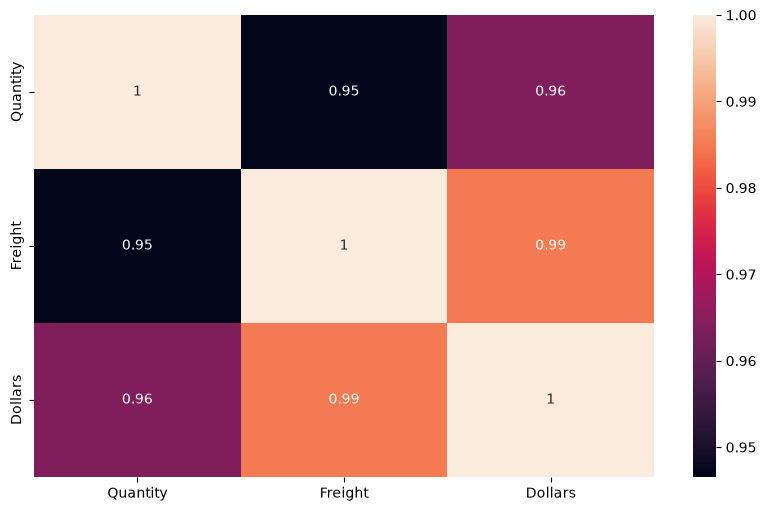

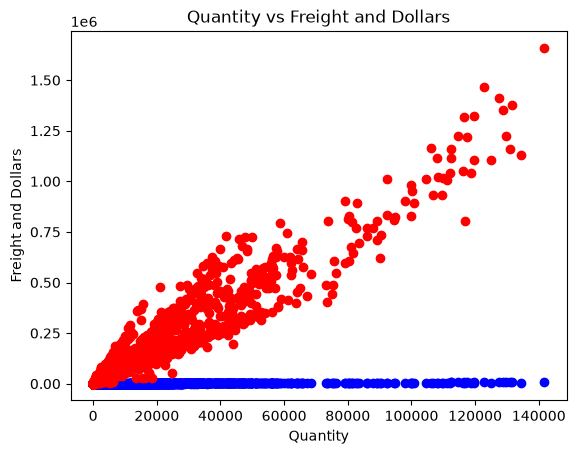

In [15]:
plt.figure(figsize=(10,6))
sns.heatmap(vendor_df[['Quantity','Freight','Dollars']].corr(),annot=True)
plt.show()

plt.scatter(vendor_df['Quantity'],vendor_df['Freight'],color='blue')
plt.scatter(vendor_df['Quantity'],vendor_df['Dollars'],color='red')
plt.title('Quantity vs Freight and Dollars')
plt.xlabel('Quantity')
plt.ylabel('Freight and Dollars')
plt.show()

In [16]:
vendor_df['freight_per_unit'] = vendor_df['Freight']/vendor_df['Quantity']
vendor_df.head()

,VendorNumber,VendorName,InvoiceDate,PONumber,PODate,PayDate,Quantity,Dollars,Freight,Approval,freight_per_unit
0,105,ALTAMAR BRANDS LLC,2024-01-04,8124,2023-12-21,2024-02-16,6,214.26,3.47,None,0.578333
1,4466,AMERICAN VINTAGE BEVERAGE,2024-01-07,8137,2023-12-22,2024-02-21,15,140.55,8.57,None,0.571333
2,388,ATLANTIC IMPORTING COMPANY,2024-01-09,8169,2023-12-24,2024-02-16,5,106.60,4.61,None,0.922000
3,480,BACARDI USA INC,2024-01-12,8106,2023-12-20,2024-02-05,10100,137483.78,2935.20,None,0.290614
4,516,BANFI PRODUCTS CORP,2024-01-07,8170,2023-12-24,2024-02-12,1935,15527.25,429.20,None,0.221809


In [18]:
low_Quantity = vendor_df['Quantity'].quantile(0.25)
high_Quantity = vendor_df['Quantity'].quantile(0.75)
print('low_Quantity:',low_Quantity)
print('high_Quantity:',high_Quantity)

low_Quantity: 83.0
high_Quantity: 5100.5


In [21]:
vendor_df.loc[vendor_df['Quantity'] < low_Quantity, 'freight_per_unit'].mean()

np.float64(0.09489854253138316)

In [22]:
vendor_df.loc[vendor_df['Quantity'] > high_Quantity, 'freight_per_unit'].mean()

np.float64(0.049077654690759046)

Feature Engineering: The model can use features such as shipment weight, distance, shipping method, and historical freight costs to make predictions.

In [59]:
x= vendor_df[['Dollars']]
y= vendor_df['Freight']

In [60]:
vendor_df.describe().round(2)

,VendorNumber,PONumber,Quantity,Dollars,Freight,freight_per_unit
count,5543.00,5543.00,5543.00,5543.00,5543.00,5543.00
mean,20662.75,10889.42,6058.88,58073.38,295.95,0.07
std,34582.16,1600.86,14453.34,140234.03,713.59,0.08
min,2.00,8106.00,1.00,4.14,0.02,0.01
25%,3089.00,9503.50,83.00,967.81,5.02,0.04
50%,7240.00,10890.00,423.00,4765.45,24.73,0.05
75%,10754.00,12275.50,5100.50,44587.18,229.66,0.07
max,201359.00,13661.00,141660.00,1660435.88,8468.22,3.11


Model Selection: Regression models like Linear Regression, Random Forest, or Gradient Boosting can be used to predict continuous freight costs.

In [33]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error


In [61]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)


In [62]:
model1= LinearRegression()
model1.fit(x_train,y_train)

model2 = DecisionTreeRegressor(max_depth=5, random_state=42)
model2.fit(x_train,y_train)

model3 = RandomForestRegressor(n_estimators=100, max_depth=5, random_state=42)
model3.fit(x_train,y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of t

In [63]:
def evaluate_mode(model,x_test,y_test, model_name):
    y_pred = model.predict(x_test)

    mse = mean_squared_error(y_test,y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test,y_pred)
    r2 = r2_score(y_test,y_pred)

    print(f"Model: {model_name}")
    print(f"MSE: {mse}")
    print(f"RMSE: {rmse}")
    print(f"MAE: {mae}")
    print(f"R²: {r2}")



In [64]:
evaluate_mode(model1,x_test,y_test,"Linear Regression")
print("\n")
evaluate_mode(model2,x_test,y_test,"Decision Tree")
print("\n")
evaluate_mode(model3,x_test,y_test,"Random Forest")

Model: Linear Regression
MSE: 15555.318371054229
RMSE: 124.72096203547433
MAE: 24.1059770728758
R²: 0.9698787714456558


Model: Decision Tree
MSE: 22592.146004021495
RMSE: 150.306839511785
MAE: 32.97258248871931
R²: 0.9562526991034435


Model: Random Forest
MSE: 17359.892637830188
RMSE: 131.75694531154775
MAE: 27.203783506953165
R²: 0.966384404269347


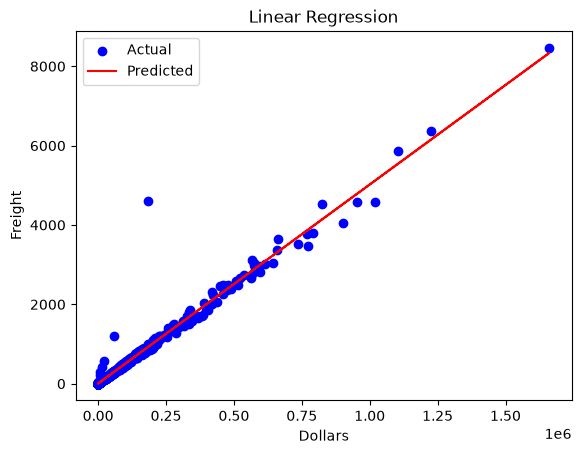

In [65]:
plt.scatter(x_test,y_test,color='blue',label='Actual')
plt.plot(x_test, model1.predict(x_test),color='red',label='Predicted')
plt.xlabel('Dollars')
plt.ylabel('Freight')
plt.title('Linear Regression')
plt.legend()
plt.show()

inferening the model: The model can be trained on historical invoice and shipment data, and then used to predict freight costs for new shipments.

In [66]:
input_data ={
    'Dollars': [1000, 2000, 3000, 4000, 5000]
}

df_input = pd.DataFrame(input_data)

In [67]:
model1.predict(df_input)

array([10.02319145, 15.03836232, 20.05353318, 25.06870405, 30.08387491])